## The Big Project begins!!

# "THE PRICE IS RIGHT" Capstone Project

This week - build a model that predicts how much something costs from a description, based on a scrape of Amazon data

# Order of play

DAY 1: Data Curation  
DAY 2: Data Pre-processing  
DAY 3: Evaluation, Baselines, Traditional ML  
DAY 4: Deep Learning and LLMs  
DAY 5: Fine-tuning a Frontier Model  

## DAY 1: Data Curation

Today we'll scrub our dataset and curate our data

The dataset is here:  
https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023

And the folder with all the product datasets is here:  
https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/tree/main/raw/meta_categories

<table style="margin: 0; text-align: left;">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/business.jpg" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#181;">Business value of Data Curation</h2>
            <span style="color:#181;">Data Curation can be considered the less glamorous work of a Data Scientist. I say that's nonsense!
            This is where the science happens - what could be more glamorous than that?! R&D with your
            dataset can often have a greater impact on performance than the fashionable 'hyper-parameter optimization' that we do later.
            So: prepare for Quality Time with Data Quality.</span>
        </td>
    </tr>
</table>

In [ ]:
pip install charset-normalizer

In [ ]:
#pip uninstall pandas -y
pip install pandas

In [1]:
# imports

import os
from dotenv import load_dotenv
from huggingface_hub import login
from datasets import load_dataset
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import numpy as np
import random
from pricer.items import Item
from pricer.parser import parse
load_dotenv(override=True)

e:\Cursos\Cursos\LLM_Engineer\llm_engineering\.venv\Lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


True

In [2]:
# Log in to HuggingFace - if you get a "Note" about Environment variable being set, ignore it

hf_token = os.environ['HF_TOKEN']
login(hf_token, add_to_git_credential=True)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


## Load our dataset

In the next cell, we load in the dataset from huggingface.

If this gives you an error like "trust_remote_code is no longer supported", then please run this command in a new cell: `!uv add --upgrade datasets==3.6.0` and then restart the Kernel, and try again.

In [3]:
dataset = load_dataset("McAuley-Lab/Amazon-Reviews-2023", "raw_meta_Appliances", split="full", trust_remote_code=True)

In [4]:
print(f"Number of Appliances: {len(dataset):,}")

Number of Appliances: 94,327


In [5]:
# Investigate a particular datapoint

dataset[6]


{'main_category': 'Appliances',
 'title': 'WD12X10327 Rack Roller and stud assembly Kit (4 Pack) by AMI PARTS Replaces AP4980629 PS3486910 1811003',
 'average_rating': 4.6,
 'rating_number': 323,
 'features': ['【PARTS NUMBER】The WD12X10327 dishwasher top rack wheels and stud assembly Kit （4 pcs）',
  '【SCOPE OF APPLICATION】The dishwasher works with most top name brands,If you are not sure if part is correct, ask us in Customer questions & answers section or visiting the AMI PARTS storefront.We’re happy to help ensure you select the correct part for your Rack Roller and stud',
  '【REPLACES PART】1811003, AP4980629, WD12X0330, WD12X0356, WD12X0357, WD12X0383, WD12X0385, WD12X10327, WD12X330, WD12X356, WD12X357, WD12X383, WD12X385',
  '【FIXES SYMPTOMS】Door won’t close | Not cleaning dishes properly | Noisy | Door latch failure',
  '【QUALITY WARRANTY】The replacement part is made from durable high quality material and well-tested by manufacturer.For any reason you’re not satisfied,you can ask

In [6]:

# What's the most expensive item?

max_price = 0
max_item = None

for datapoint in tqdm(dataset):
    try:
        price = float(datapoint["price"])
        if price > max_price:
            max_item = datapoint
            max_price = price
    except ValueError:
        pass

print(f"The most expensive item is {max_item['title']} and it costs {max_price:,.2f}")

  0%|          | 0/94327 [00:00<?, ?it/s]

The most expensive item is TurboChef BULLET Rapid Cook Electric Microwave Convection Oven and it costs 21,095.62


This is the closest I can find - looks like it's going at a bargain price!!

https://www.amazon.com/TurboChef-Electric-Countertop-Microwave-Convection/dp/B01D05U9NO/

In [7]:
# Load into Item objects if they have a price range $1-$1000 and enough details

items = [parse(datapoint, "Appliances") for datapoint in tqdm(dataset)]
items = [item for item in items if item is not None]
print(f"There are {len(items):,} items from {len(dataset):,} datapoints")

  0%|          | 0/94327 [00:00<?, ?it/s]

There are 35,307 items from 94,327 datapoints


In [8]:
items[0]

<WD12X10327 Rack Roller and stud assembly Kit (4 Pack) by AMI PARTS Replaces AP4980629 PS3486910 1811003 = $8.99>

In [9]:
print(items[0].full)

Rack Roller and stud assembly Kit (4 Pack) by AMI PARTS Replaces   1811003
['【PARTS NUMBER】The  dishwasher top rack wheels and stud assembly Kit （4 pcs）', '【SCOPE OF 】The dishwasher works with most top name brands,If you are not sure if part is correct, ask us in Customer questions & answers section or visiting the AMI PARTS storefront.We’re happy to help ensure you select the correct part for your Rack Roller and stud', '【 PART】, , , , , , , , , , , , ', '【FIXES SYMPTOMS】Door won’t close | Not cleaning dishes properly | Noisy | Door latch failure', '【QUALITY WARRANTY】The replacement part is made from durable high quality material and well-tested by manufacturer.For any reason you’re not satisfied,you can ask for a replacement or full refund']
{"Brand Name": "AMI PARTS", "Model Info": "", "Item Weight": "0.634 ounces", "Color": "White", "Material Type": "Plastic", "Date First Available": "July 14, 2019", "Brand": "AMI PARTS", "Material": "Plastic", "Model Name": " Rack Roller and stud 

In [10]:
prices = [item.price for item in items]
lengths = [len(item.full) for item in items]

In [13]:
len(lengths)

35307

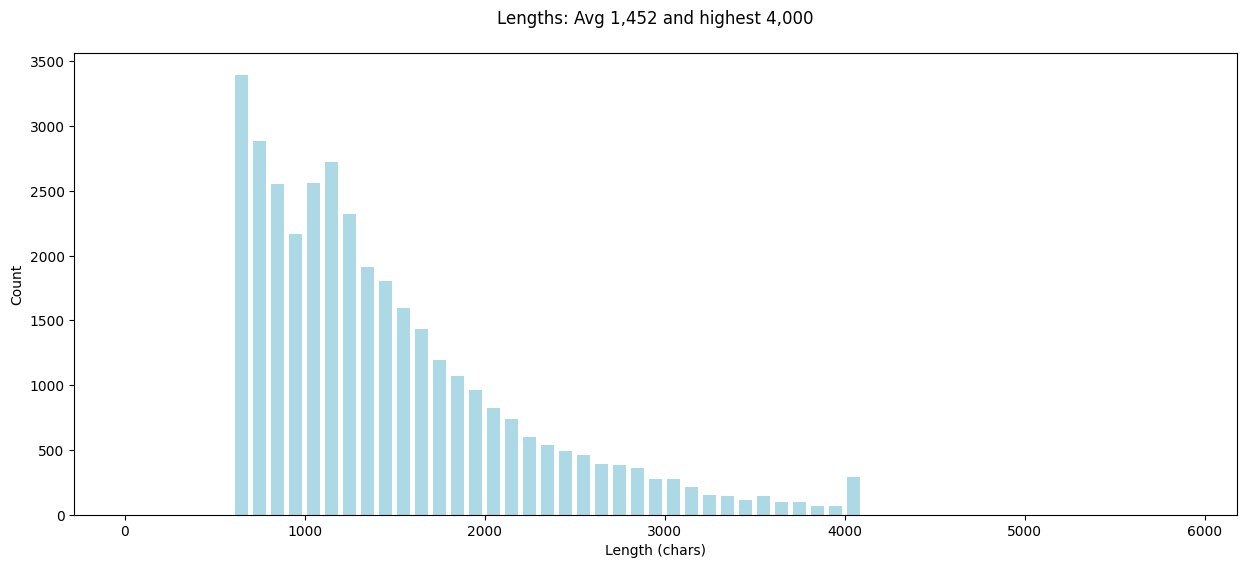

In [11]:
# Plot the distribution of lengths

plt.figure(figsize=(15, 6))
plt.title(f"Lengths: Avg {sum(lengths)/len(lengths):,.0f} and highest {max(lengths):,}\n")
plt.xlabel('Length (chars)')
plt.ylabel('Count')
plt.hist(lengths, rwidth=0.7, color="lightblue", bins=range(0, 6000, 100))
plt.show()

In [14]:
max_length = max(lengths)
max_length_item = items[lengths.index(max_length)]
print(max_length_item.full)


Polyester Dryer Vent Filters Replacement Part by Beaquicy Replacement for Better vent Indoor Dryer Vent Packs of 12
['✅【 AIR 】--- The polyester filters provide optimal air conditioning for your dryer and keep it away from polluted air. Because these parts will rate to trap fine lint and dust particles, protect your home from unwanted bacteria and other unfriendly dust particles and can be vacuumed clean or replaced when fully loaded with lint. so that the air in your room is cleaner than ever. While protecting your indoor quality, clothes can dry faster. It helps improve the indoor air quality.', '✅【HIGH-GRADE 】--- The package includes 12 x replacement polyester filters for bettervent.They are well-made from durable and high-grade polyester which can traps fine lint and dust particles, optimize the cleaning process and prolong lifetime. Each filter protects up to 5 dryer loads! For best results insert blue side facing towards dryer vent.', '✅【WIDE 】--- These polyester filters are desig

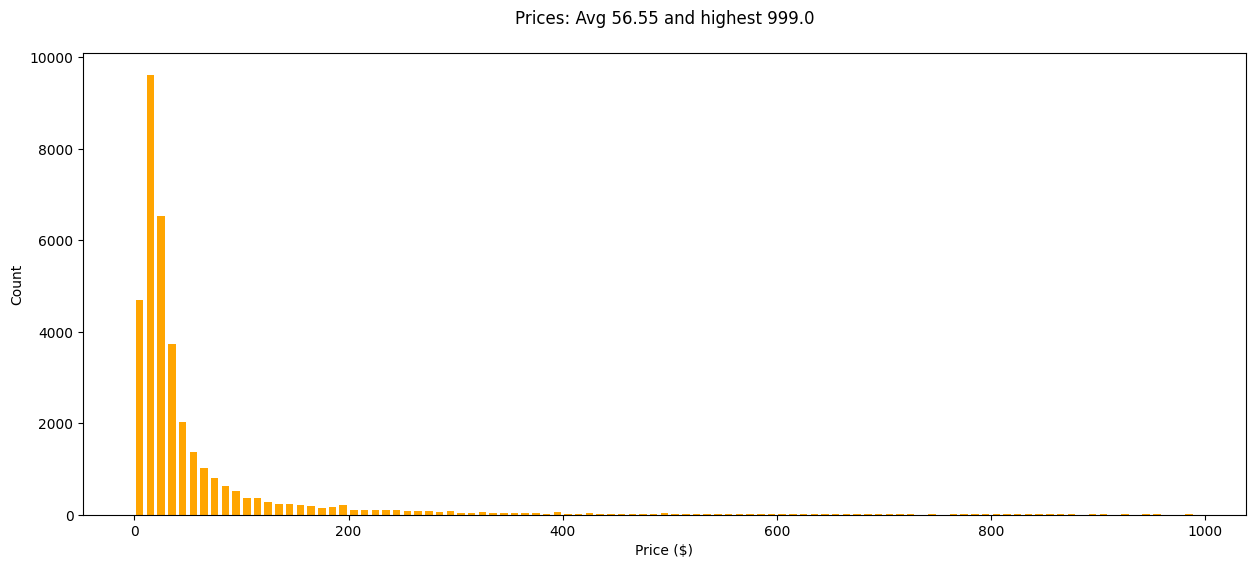

In [13]:
# Plot the distribution of prices
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.2f} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="orange", bins=range(0, 1000, 10))
plt.show()

In [15]:
print(items[3].full)

MLGB Stainless Steel Brushed Pattern Dishwasher Magnet Cover Panel Decal Home Appliance Art, Stainless Steel Fridge Door Cover Decals Magnetic, Black, Mobile Magnetic 23" x 26"
['Stainless Steel Brushed Pattern Magnetic Dishwasher Panel Covers allow you to easily transform your kitchen as the seasons change. You can instantly get rid of outdated and/or mismatched appliances, will give your kitchen a refreshing look.', ':', 'Vinyl + rubber magnet', 'Occasion:', 'Magnet Dishwasher Cover Decor dishwasher covers and any metal device surface with magnetism.', '【Kitchen Dishwasher Covers SIZE】S - 23 W x 17 H inches; 58.5 W x 43 H cm;L - 23 W x 26 H inches; 58.5 W x 66 H cm;', 'Attention:', 'Just ensure that your dishwasher is magnetic before ordering the dishwasher cover magnet', 'Due to the inconsistent calibration of the monitor, the colors on the computer monitor may be slightly different.', 'Quality service:', 'If you have any questions or questions, please feel free to contact us and we

In [16]:
from pricer.loaders import ItemLoader
loader = ItemLoader("Appliances")
items = loader.load()


Loading dataset Appliances


100%|██████████| 95/95 [00:18<00:00,  5.23it/s]


Completed Appliances with 35,307 datapoints in 0.4 mins


In [17]:

dataset_names = [
    "Automotive",
    "Electronics",
    "Office_Products",
    "Tools_and_Home_Improvement",
    "Cell_Phones_and_Accessories",
    "Toys_and_Games",
    "Appliances",
    "Musical_Instruments",
]

import psutil

print(
    f"RAM usada: {psutil.virtual_memory().used/1024**3:.2f} GB"
)

import os
import psutil

proc = psutil.Process(os.getpid())

print(
    f"PID={os.getpid()} "
    f"RAM={proc.memory_info().rss/1024**3:.2f} GB"
)

import os
import psutil

proc = psutil.Process(os.getpid())

print(
    f"PID={os.getpid()} "
    f"RAM={proc.memory_info().rss/1024**3:.2f} GB "
    #f"FILAS={len(loaders['Appliances'].items)}"
)

import pickle

size_mb = len(pickle.dumps(resultado)) / 1024**2

print(f"Tamaño retorno: {size_mb:.2f} MB")

import gc

items = []
for dataset_name in dataset_names:
    loader = ItemLoader(dataset_name)
    new_items = loader.load()
    items.extend(new_items)
    print(f"✅ {dataset_name}: {len(new_items):,} items | Total acumulado: {len(items):,}")
    del new_items
    gc.collect()  # Libera memoria antes del siguiente dataset

print(f"\nTotal final: {len(items):,} items")

In [17]:
import os
os.environ["HF_HOME"] = "E:/huggingface_cache"
os.environ["HF_DATASETS_CACHE"] = "E:/huggingface_cache/datasets"

In [ ]:
import shutil
from pathlib import Path

# Carpeta del dataset específico que falló
cache_c = Path("C:/Users/patri/.cache/huggingface/datasets/McAuley-Lab___amazon-reviews-2023")

if cache_c.exists():
    print(f"🗑️ Borrando caché en C: ...")
    #shutil.rmtree(cache_c)
    print("✅ Borrado")
else:
    print("✅ No existe, ya estaba limpio")

In [ ]:
import shutil
from pathlib import Path

# Limpia archivos .incomplete del dataset fallido
cache_path = Path("E:/huggingface_cache/datasets/McAuley-Lab___amazon-reviews-2023")

incomplete_files = list(cache_path.rglob("*.incomplete"))
if incomplete_files:
    print(f"🗑️ Encontrados {len(incomplete_files)} archivos .incomplete:")
    for f in incomplete_files:
        print(f"   {f}")
        f.unlink()
    print("✅ Limpiados")
else:
    print("✅ No hay archivos .incomplete")

In [19]:
import psutil
mem = psutil.virtual_memory()
print(f"Total:     {mem.total/1024**3:.1f} GB")
print(f"Disponible:{mem.available/1024**3:.1f} GB")
print(f"Usada:     {mem.percent:.1f}%")

Total:     7.9 GB
Disponible:0.8 GB
Usada:     89.2%


In [20]:
import inspect
from pricer.loaders import ItemLoader
print(inspect.signature(ItemLoader.load))
print(inspect.signature(ItemLoader.load_in_parallel))

(self, workers=11)
(self, workers)


In [ ]:
import gc
import os
import json
import pickle
import psutil
from pathlib import Path

# ── Configuración ──────────────────────────────────────────────
CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)
CHECKPOINT_FILE = CHECKPOINT_DIR / "progress.json"
ITEMS_FILE      = CHECKPOINT_DIR / "items.pkl"

def get_stats():
    proc = psutil.Process(os.getpid())
    mem  = psutil.virtual_memory()
    return (
        psutil.cpu_percent(interval=0.1),
        proc.memory_info().rss / 1024**2,
        mem.percent,
        mem.available / 1024**3,
    )

def load_checkpoint():
    """Carga el progreso guardado (datasets completados + items acumulados)."""
    completed = []
    items = []

    if CHECKPOINT_FILE.exists():
        with open(CHECKPOINT_FILE) as f:
            data = json.load(f)
            completed = data.get("completed", [])
        print(f"📂 Checkpoint encontrado: {len(completed)} datasets ya completados: {completed}")

    if ITEMS_FILE.exists() and completed:
        print(f"📦 Cargando items guardados desde disco...")
        with open(ITEMS_FILE, "rb") as f:
            items = pickle.load(f)
        print(f"   → {len(items):,} items recuperados")

    return completed, items

def save_checkpoint(completed_datasets, items):
    """Guarda progreso a disco."""
    with open(CHECKPOINT_FILE, "w") as f:
        json.dump({"completed": completed_datasets}, f)
    with open(ITEMS_FILE, "wb") as f:
        pickle.dump(items, f)
    size_mb = ITEMS_FILE.stat().st_size / 1024**2
    print(f"   💾 Checkpoint guardado ({size_mb:.0f} MB en disco)")

def clear_checkpoint():
    """Limpia checkpoints al finalizar con éxito."""
    for f in [CHECKPOINT_FILE, ITEMS_FILE]:
        if f.exists():
            f.unlink()
    print("🧹 Checkpoints eliminados (proceso completado)")

# ── Carga con checkpoint ────────────────────────────────────────
completed_datasets, items = load_checkpoint()

print(f"\n{'Dataset':<30} {'Nuevos':>8} {'Total':>10} {'CPU%':>6} {'ProcMB':>8} {'SysMem%':>8} {'LibreGB':>8}")
print("─" * 85)

failed_dataset = None

for dataset_name in dataset_names:

    # ✅ Ya completado: saltar
    if dataset_name in completed_datasets:
        print(f"{'⏭️  ' + dataset_name:<30} {'(ya cargado)':>8}")
        continue

    print(f"\n⏳ Cargando: {dataset_name} ...")
    try:
        loader = ItemLoader(dataset_name)
        new_items = loader.load(workers=1)
        count = len(new_items)
        items.extend(new_items)
        del new_items
        gc.collect()

        completed_datasets.append(dataset_name)
        save_checkpoint(completed_datasets, items)  # guarda tras cada éxito

        cpu, proc_mb, sys_pct, free_gb = get_stats()
        print(
            f"{'✅ ' + dataset_name:<30} {count:>8,} {len(items):>10,} "
            f"{cpu:>5.1f}% {proc_mb:>7.0f} {sys_pct:>7.1f}% {free_gb:>7.2f}"
        )

        # ⚠️ Alerta si la RAM disponible baja de 2 GB
        if free_gb < 2.0:
            print(f"   ⚠️  RAM disponible baja ({free_gb:.2f} GB) — considera reiniciar el kernel")

    except Exception as e:
        failed_dataset = dataset_name
        print(f"\n❌ Error en '{dataset_name}': {e}")
        print(f"   El progreso hasta aquí fue guardado. Vuelve a ejecutar para retomar.")
        break

# ── Resultado final ─────────────────────────────────────────────
if failed_dataset is None:
    print("─" * 85)
    cpu, proc_mb, sys_pct, free_gb = get_stats()
    print(f"\n🎉 Total final: {len(items):,} items")
    print(f"   CPU: {cpu:.1f}% | Proceso: {proc_mb:.0f} MB | Sistema: {sys_pct:.1f}% | Libre: {free_gb:.2f} GB")
    clear_checkpoint()  # limpia solo si todo salió bien
else:
    print(f"\n⏸️  Proceso pausado en '{failed_dataset}'")
    print(f"   Datasets completados: {completed_datasets}")
    print(f"   Items guardados: {len(items):,}")
    print(f"   → Vuelve a ejecutar esta celda para retomar automáticamente")

📂 Checkpoint encontrado: 4 datasets ya completados: ['Automotive', 'Electronics', 'Office_Products', 'Tools_and_Home_Improvement']
📦 Cargando items guardados desde disco...
   → 2,239,407 items recuperados

Dataset                          Nuevos      Total   CPU%   ProcMB  SysMem%  LibreGB
─────────────────────────────────────────────────────────────────────────────────────
⏭️  Automotive                 (ya cargado)
⏭️  Electronics                (ya cargado)
⏭️  Office_Products            (ya cargado)
⏭️  Tools_and_Home_Improvement (ya cargado)

⏳ Cargando: Cell_Phones_and_Accessories ...
Loading dataset Cell_Phones_and_Accessories


  0%|          | 0/1289 [00:07<?, ?it/s]



❌ Error en 'Cell_Phones_and_Accessories': A process in the process pool was terminated abruptly while the future was running or pending.
   El progreso hasta aquí fue guardado. Vuelve a ejecutar para retomar.

⏸️  Proceso pausado en 'Cell_Phones_and_Accessories'
   Datasets completados: ['Automotive', 'Electronics', 'Office_Products', 'Tools_and_Home_Improvement']
   Items guardados: 2,239,407
   → Vuelve a ejecutar esta celda para retomar automáticamente


import gc
import os
import json
import pickle
import psutil
from pathlib import Path

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)
CHECKPOINT_FILE = CHECKPOINT_DIR / "progress.json"
ITEMS_DIR       = CHECKPOINT_DIR / "items_por_dataset"  # cada dataset en su propio archivo
ITEMS_DIR.mkdir(exist_ok=True)

def get_stats():
    proc = psutil.Process(os.getpid())
    mem  = psutil.virtual_memory()
    return (
        psutil.cpu_percent(interval=0.1),
        proc.memory_info().rss / 1024**2,
        mem.percent,
        mem.available / 1024**3,
    )

def load_checkpoint():
    completed = []
    if CHECKPOINT_FILE.exists():
        with open(CHECKPOINT_FILE) as f:
            completed = json.load(f).get("completed", [])
        print(f"📂 Checkpoint: {len(completed)} datasets completados: {completed}")
    return completed

def save_checkpoint(completed_datasets, dataset_name, new_items):
    """Guarda cada dataset en su propio archivo — no acumula todo en RAM."""
    item_file = ITEMS_DIR / f"{dataset_name}.pkl"
    with open(item_file, "wb") as f:
        pickle.dump(new_items, f)
    with open(CHECKPOINT_FILE, "w") as f:
        json.dump({"completed": completed_datasets}, f)
    size_mb = item_file.stat().st_size / 1024**2
    print(f"   💾 Guardado {dataset_name}.pkl ({size_mb:.0f} MB)")

def merge_all_items():
    """Junta todo al final, una vez que todos los datasets están descargados."""
    print("\n📦 Uniendo todos los datasets...")
    all_items = []
    for pkl_file in sorted(ITEMS_DIR.glob("*.pkl")):
        with open(pkl_file, "rb") as f:
            items = pickle.load(f)
        all_items.extend(items)
        print(f"   {pkl_file.stem}: {len(items):,} items")
        del items
        gc.collect()
    return all_items

# ── Carga con checkpoint ────────────────────────────────────────
completed_datasets = load_checkpoint()

print(f"\n{'Dataset':<35} {'Nuevos':>8} {'CPU%':>6} {'ProcMB':>8} {'LibreGB':>8}")
print("─" * 70)

failed_dataset = None

for dataset_name in dataset_names:
    if dataset_name in completed_datasets:
        print(f"⏭️  {dataset_name:<33} (ya cargado)")
        continue

    print(f"\n⏳ Cargando: {dataset_name} ...")
    
    # Libera RAM antes de cada dataset
    gc.collect()
    _, _, _, free_gb = get_stats()
    print(f"   RAM libre antes: {free_gb:.2f} GB")

    try:
        loader = ItemLoader(dataset_name)
        new_items = loader.load(workers=1)  # ← 1 solo worker
        count = len(new_items)

        save_checkpoint(completed_datasets + [dataset_name], dataset_name, new_items)
        completed_datasets.append(dataset_name)

        del new_items
        gc.collect()

        cpu, proc_mb, _, free_gb = get_stats()
        print(f"✅ {dataset_name:<33} {count:>8,} {cpu:>5.1f}% {proc_mb:>7.0f} {free_gb:>7.2f}")

    except Exception as e:
        failed_dataset = dataset_name
        print(f"\n❌ Error en '{dataset_name}': {e}")
        break

# ── Merge final ─────────────────────────────────────────────────
if failed_dataset is None:
    items = merge_all_items()
    print(f"\n🎉 Total final: {len(items):,} items")
else:
    print(f"\n⏸️  Pausado en '{failed_dataset}' — vuelve a ejecutar para retomar")

In [18]:
import gc
import os
import json
import pickle
import psutil
from pathlib import Path

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)
CHECKPOINT_FILE = CHECKPOINT_DIR / "progress.json"
ITEMS_DIR       = CHECKPOINT_DIR / "items_por_dataset"
ITEMS_DIR.mkdir(exist_ok=True)

# Archivo final — se va escribiendo dataset por dataset
FINAL_FILE = Path("checkpoints/items.pkl")

def get_stats():
    proc = psutil.Process(os.getpid())
    mem  = psutil.virtual_memory()
    return (
        psutil.cpu_percent(interval=0.1),
        proc.memory_info().rss / 1024**2,
        mem.percent,
        mem.available / 1024**3,
    )

def load_checkpoint():
    completed = []
    if CHECKPOINT_FILE.exists():
        with open(CHECKPOINT_FILE) as f:
            completed = json.load(f).get("completed", [])
        print(f"📂 Checkpoint: {len(completed)} datasets completados: {completed}")
    return completed

def append_to_final(new_items):
    """Agrega items al archivo final leyendo y reescribiendo en chunks."""
    if FINAL_FILE.exists():
        with open(FINAL_FILE, "rb") as f:
            existing = pickle.load(f)
    else:
        existing = []
    existing.extend(new_items)
    with open(FINAL_FILE, "wb") as f:
        pickle.dump(existing, f)
    count = len(existing)
    del existing
    gc.collect()
    return count

def save_checkpoint(completed_datasets):
    with open(CHECKPOINT_FILE, "w") as f:
        json.dump({"completed": completed_datasets}, f)

# ── Main ────────────────────────────────────────────────────────
completed_datasets = load_checkpoint()

# Cuenta items ya guardados
total_saved = 0
if FINAL_FILE.exists():
    with open(FINAL_FILE, "rb") as f:
        existing = pickle.load(f)
        total_saved = len(existing)
        del existing
        gc.collect()
    print(f"📦 items_final.pkl existente: {total_saved:,} items")

print(f"\n{'Dataset':<35} {'Nuevos':>8} {'Total':>10} {'LibreGB':>8}")
print("─" * 65)

failed_dataset = None

for dataset_name in dataset_names:
    if dataset_name in completed_datasets:
        print(f"⏭️  {dataset_name:<33} (ya cargado)")
        continue

    gc.collect()
    _, _, _, free_gb = get_stats()
    print(f"\n⏳ {dataset_name} | RAM libre: {free_gb:.2f} GB")

    try:
        loader = ItemLoader(dataset_name)
        new_items = loader.load(workers=1)
        count = len(new_items)

        total_saved = append_to_final(new_items)
        del new_items
        gc.collect()

        completed_datasets.append(dataset_name)
        save_checkpoint(completed_datasets)

        _, _, _, free_gb = get_stats()
        print(f"✅ {dataset_name:<33} {count:>8,} {total_saved:>10,} {free_gb:>7.2f}")

    except Exception as e:
        failed_dataset = dataset_name
        print(f"\n❌ Error en '{dataset_name}': {e}")
        break

if failed_dataset is None:
    print(f"\n🎉 Completado — {total_saved:,} items en checkpoints/items.pkl")
else:
    print(f"\n⏸️  Pausado en '{failed_dataset}' — vuelve a ejecutar para retomar")
    print(f"   Items guardados hasta ahora: {total_saved:,}")

📂 Checkpoint: 8 datasets completados: ['Automotive', 'Electronics', 'Office_Products', 'Tools_and_Home_Improvement', 'Cell_Phones_and_Accessories', 'Toys_and_Games', 'Appliances', 'Musical_Instruments']
📦 items_final.pkl existente: 2,239,407 items

Dataset                               Nuevos      Total  LibreGB
─────────────────────────────────────────────────────────────────
⏭️  Automotive                        (ya cargado)
⏭️  Electronics                       (ya cargado)
⏭️  Office_Products                   (ya cargado)
⏭️  Tools_and_Home_Improvement        (ya cargado)
⏭️  Cell_Phones_and_Accessories       (ya cargado)
⏭️  Toys_and_Games                    (ya cargado)
⏭️  Appliances                        (ya cargado)
⏭️  Musical_Instruments               (ya cargado)

🎉 Completado — 2,239,407 items en checkpoints/items.pkl


In [23]:
# Ejecuta esto UNA sola vez para migrar
import pickle, json
from pathlib import Path

# Carga el pickle viejo con todos los items juntos
old_items_file = Path("checkpoints/items.pkl")
completed = json.load(open("checkpoints/progress.json"))["completed"]

print("Cargando antiguo items.pkl ...")
with open(old_items_file, "rb") as f:
    #all_items = pickle.load(f)
    all_items = pickle.load(f)
# Los separa en archivos individuales
# (no sabemos cuántos tiene cada uno, los guarda todos en uno llamado "legacy")
ITEMS_DIR = Path("checkpoints/items_por_dataset")
ITEMS_DIR.mkdir(exist_ok=True)

# Guarda todo lo anterior junto como "legacy" para no perderlo
with open(ITEMS_DIR / "_legacy_4_datasets.pkl", "wb") as f:
    pickle.dump(all_items, f)

del all_items
print("✅ Migrado")

Cargando antiguo items.pkl ...
✅ Migrado


In [20]:
def process_in_batches(filepath, batch_size=100):
    """Procesa lotes pequeños desde disco"""
    
    batch = []
    with open(filepath, 'r') as f:
        for line in f:
            item = json.loads(line)
            batch.append(item)
            
            if len(batch) >= batch_size:
                # Procesa el lote
                results = process_batch(batch)
                save_results(results)  # Guarda resultados inmediatamente
                batch = []  # Limpia el lote
                
        # Procesa el último lote si existe
        if batch:
            process_batch(batch)

In [30]:
items = []
for dataset_name in dataset_names:
    loader = ItemLoader(dataset_name)
    items.extend(loader.load())

Loading dataset Automotive


100%|██████████| 2004/2004 [18:40<00:00,  1.79it/s]


Completed Automotive with 974,469 datapoints in 19.0 mins
Loading dataset Electronics


 61%|██████    | 983/1611 [10:57<07:00,  1.49it/s]


BrokenProcessPool: A process in the process pool was terminated abruptly while the future was running or pending.

In [24]:
print(f"A grand total of {len(items):,} items")

A grand total of 35,307 items


In [23]:
items[1000]

<MORE Pure MPF16095 Refrigerator Water Filter Compatible with LG LT800P and Kenmore 46-9460 = $19.95>

In [26]:
random.seed(42)
random.shuffle(items)

seen = set()
items = [x for x in tqdm(items) if not (x.title in seen or seen.add(x.title))]

seen = set()
items = [x for x in tqdm(items) if not (x.full in seen or seen.add(x.full))]

del seen
print(f"After deduplication, we have {len(items):,} items")

  0%|          | 0/32721 [00:00<?, ?it/s]

  0%|          | 0/32721 [00:00<?, ?it/s]

After deduplication, we have 32,721 items


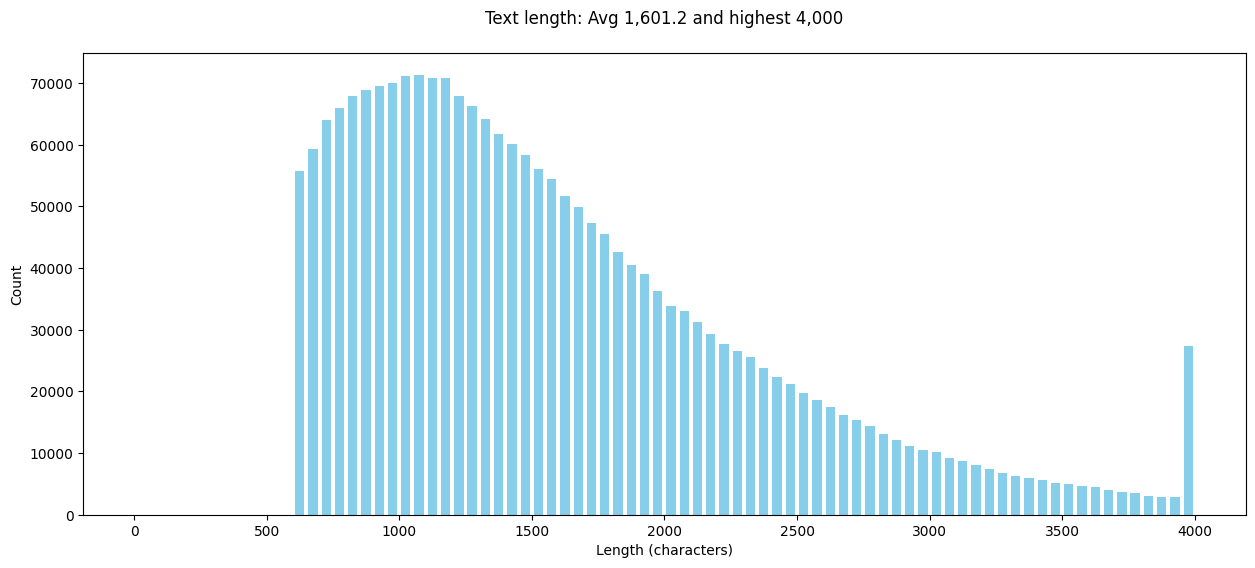

In [28]:
lengths = [len(item.full) for item in items]
plt.figure(figsize=(15, 6))
plt.title(f"Text length: Avg {sum(lengths)/len(lengths):,.1f} and highest {max(lengths):,}\n")
plt.xlabel('Length (characters)')
plt.ylabel('Count')
plt.hist(lengths, rwidth=0.7, color="skyblue", bins=range(0, 4050, 50))
plt.show()

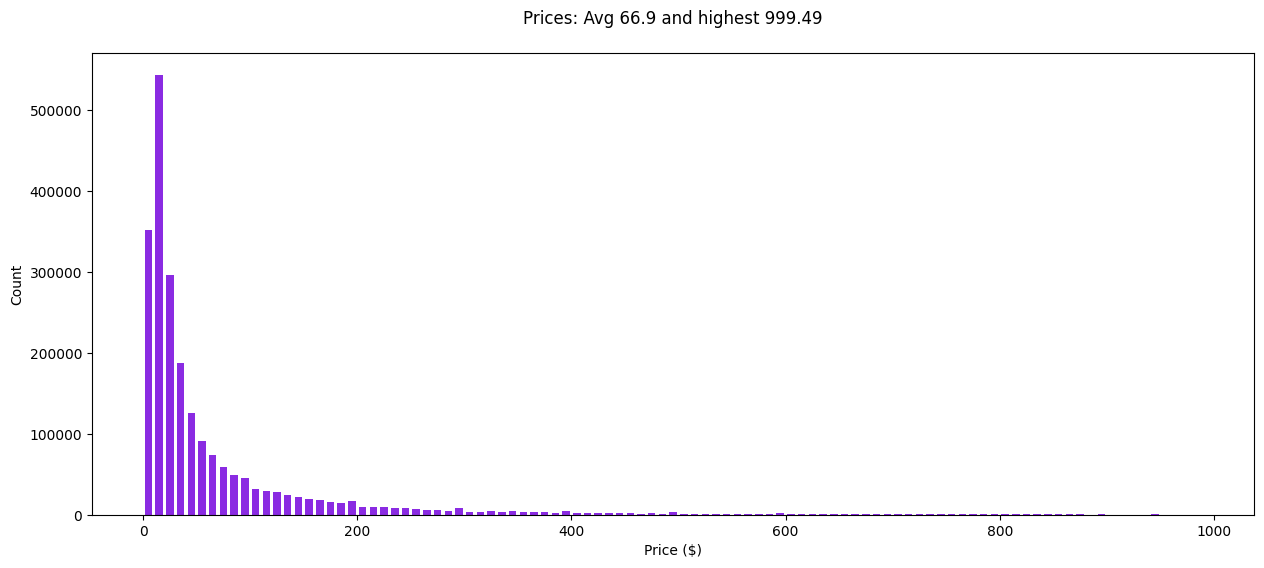

In [29]:
# Plot the distribution of prices

prices = [item.price for item in items]
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.1f} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
plt.show()

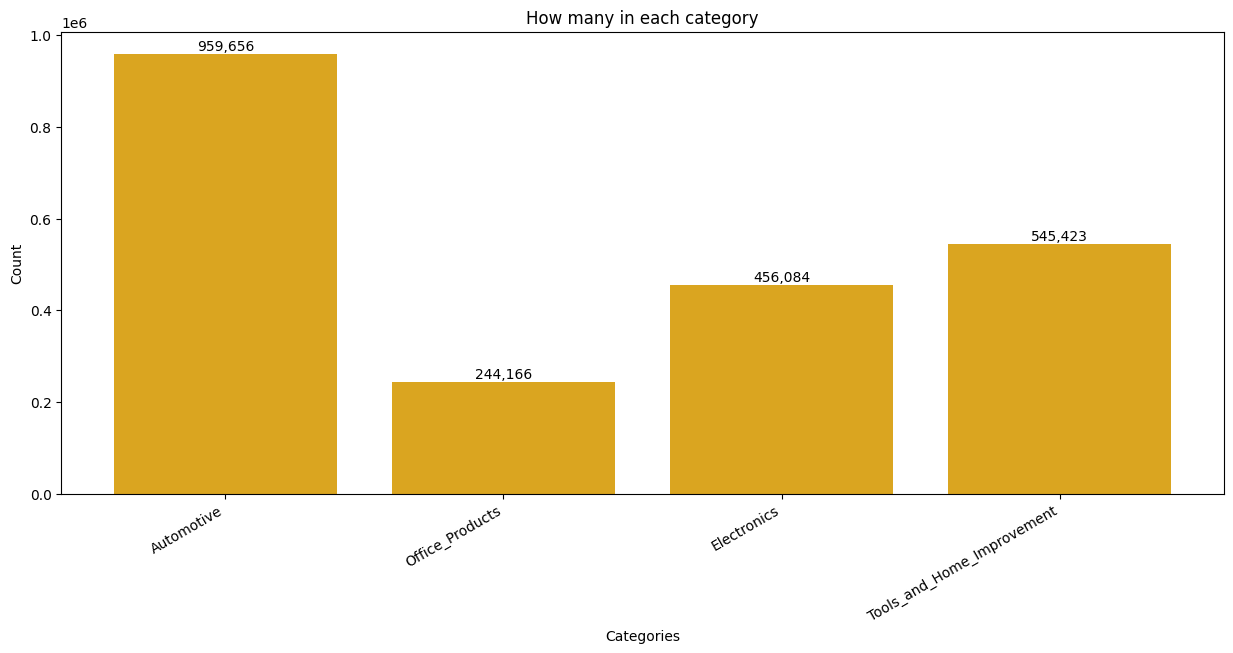

In [30]:
from collections import Counter
category_counts = Counter([item.category for item in items])

categories = category_counts.keys()
counts = [category_counts[category] for category in categories]

plt.figure(figsize=(15, 6))
plt.bar(categories, counts, color="goldenrod")
plt.title('How many in each category')
plt.xlabel('Categories')
plt.ylabel('Count')
plt.xticks(rotation=30, ha='right')

for i, v in enumerate(counts):
    plt.text(i, v, f"{v:,}", ha='center', va='bottom')

plt.show()

In [27]:
print(f"Items disponibles: {len(items):,}")
print(f"Sample solicitado: {SIZE:,}")

Items disponibles: 32,721
Sample solicitado: 820,000


In [28]:
np.random.seed(42)

SIZE = 820_000

prices = np.array([it.price for it in items], dtype=float)
categories = np.array([it.category for it in items])
p = (prices - prices.min()) / (prices.max() - prices.min() + 1e-9)

w = p**2
w[categories == "Tools_and_Home_Improvement"] *= 0.5
w[categories == "Automotive"] *= 0.05

w = w / w.sum()
idx = np.random.choice(len(items), size=SIZE, replace=False, p=w)
sample = [items[i] for i in idx]


ValueError: Cannot take a larger sample than population when 'replace=False'

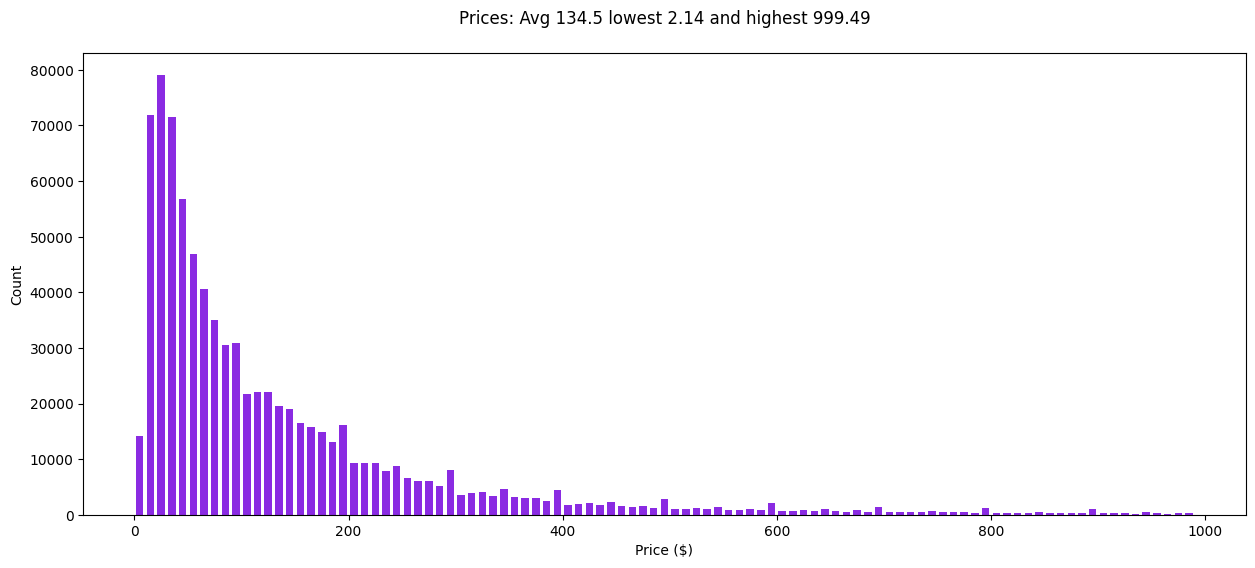

In [32]:
prices = [item.price for item in sample]
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.1f} lowest {min(prices):,} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
plt.show()

In [29]:
# Just for good measure, let's shuffle the sample again for the final dataset

random.seed(42)
random.shuffle(sample)


NameError: name 'sample' is not defined

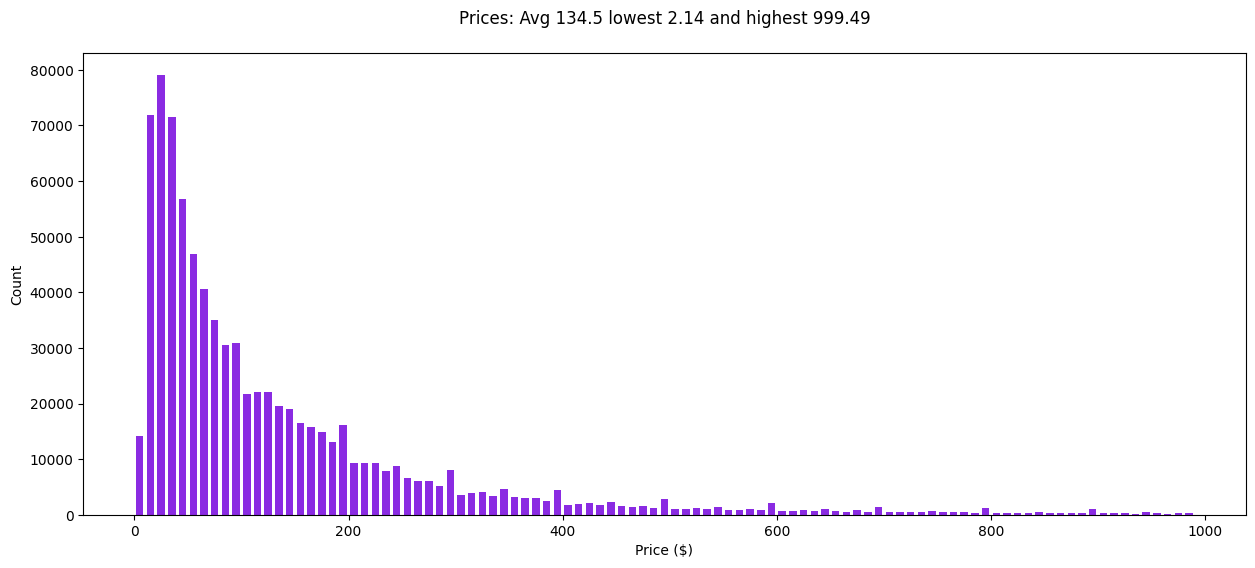

In [34]:
prices = [item.price for item in sample]
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.1f} lowest {min(prices):,} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
plt.show()

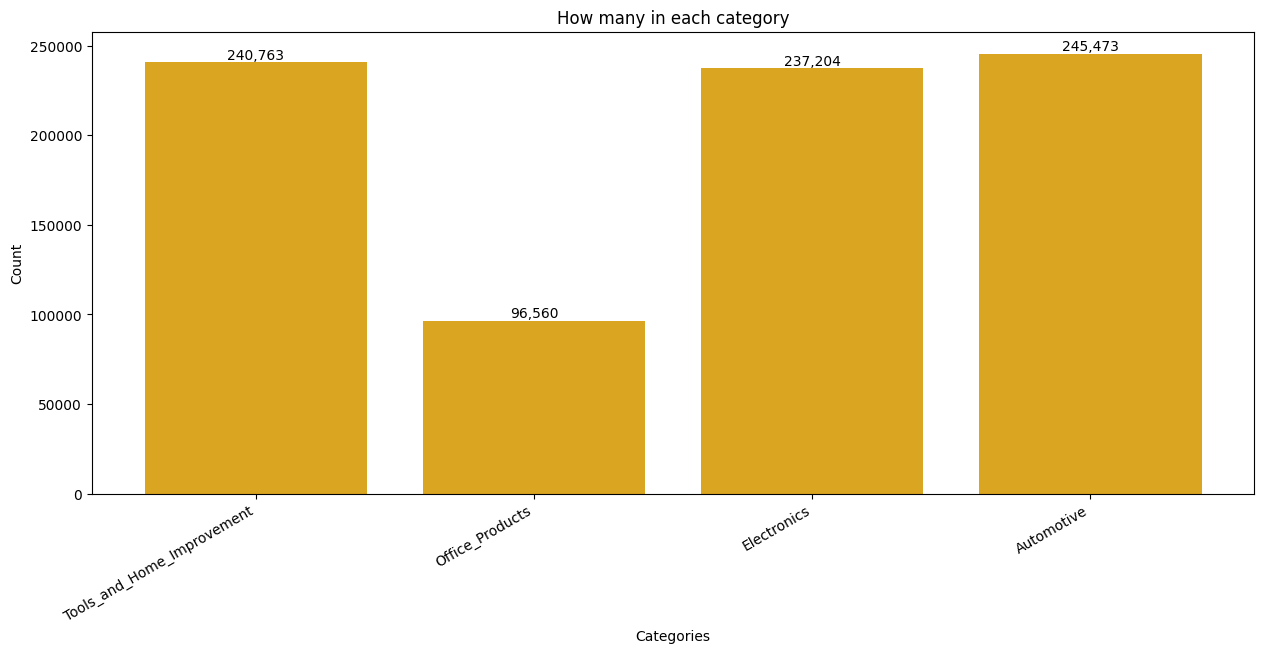

In [35]:
from collections import Counter
category_counts = Counter([item.category for item in sample])

categories = category_counts.keys()
counts = [category_counts[category] for category in categories]

# Bar chart by category
plt.figure(figsize=(15, 6))
plt.bar(categories, counts, color="goldenrod")
plt.title('How many in each category')
plt.xlabel('Categories')
plt.ylabel('Count')

plt.xticks(rotation=30, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(counts):
    plt.text(i, v, f"{v:,}", ha='center', va='bottom')

# Display the chart
plt.show()

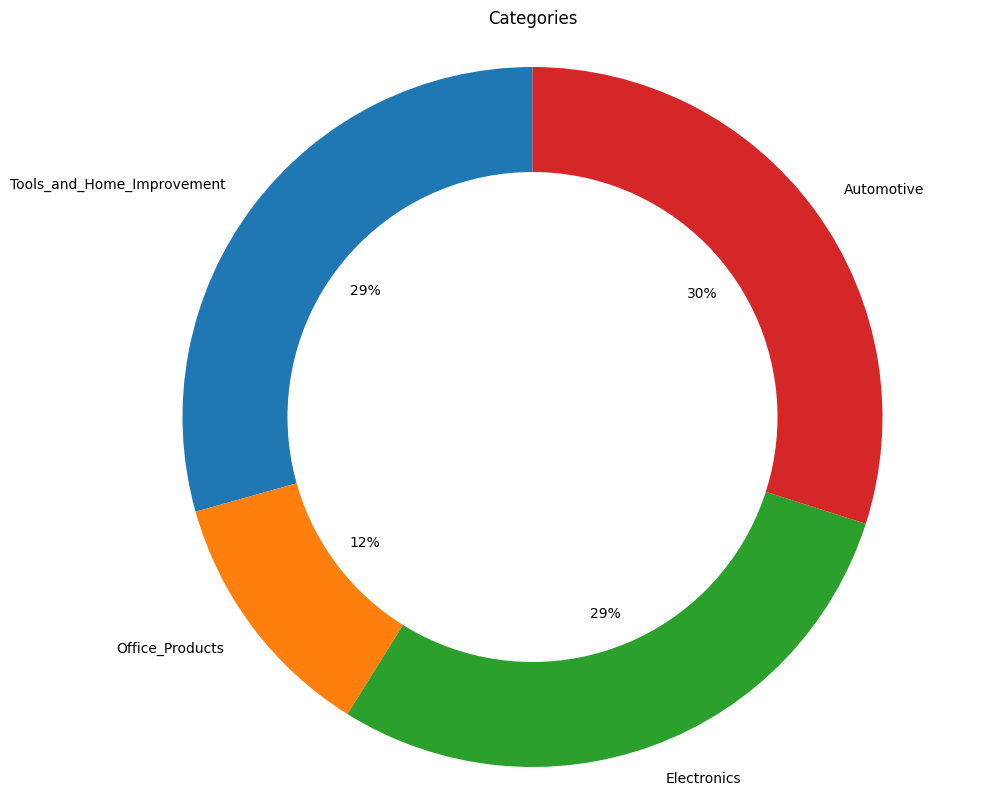

In [36]:
# Automotive still in the lead, but improved somewhat
# For another perspective, let's look at a pie

plt.figure(figsize=(12, 10))
plt.pie(counts, labels=categories, autopct='%1.0f%%', startangle=90)

# Add a circle at the center to create a donut chart (optional)
centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
plt.title('Categories')

# Equal aspect ratio ensures that pie is drawn as a circle
plt.axis('equal')  

plt.show()

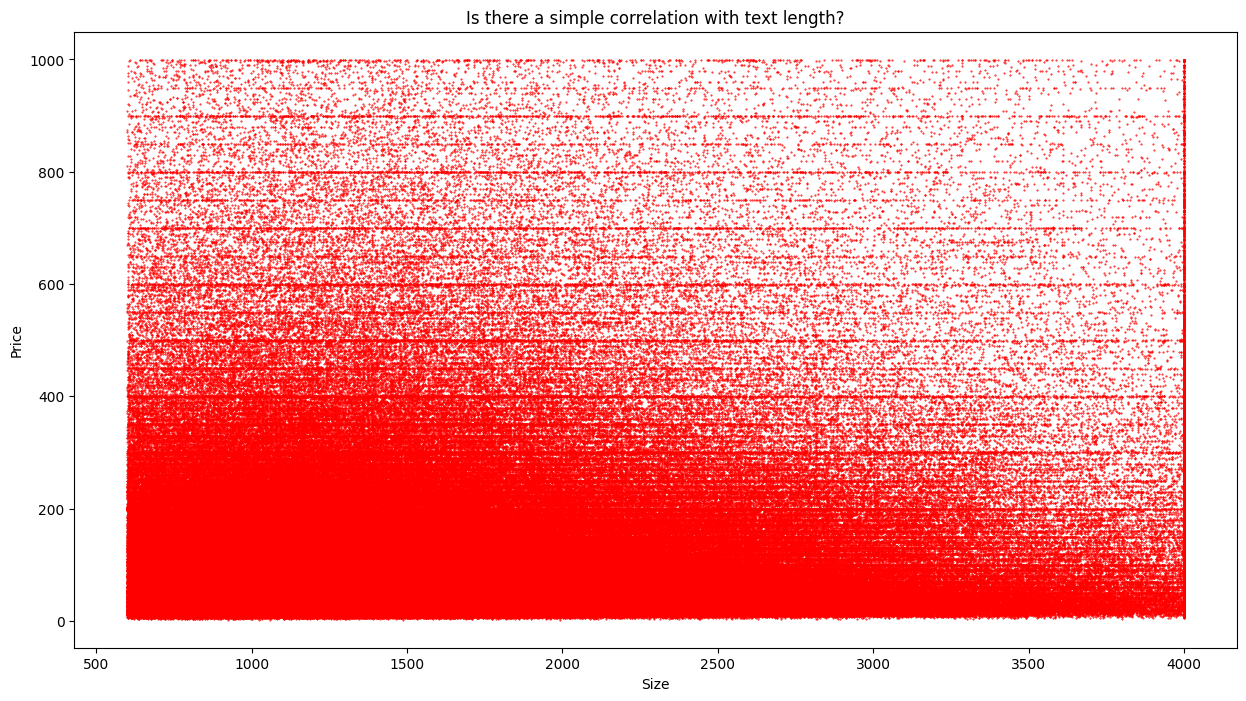

In [37]:
# How does the price vary with the character count?

sizes = [len(item.full) for item in sample]
prices = [item.price for item in sample]

# Create the scatter plot
plt.figure(figsize=(15, 8))
plt.scatter(sizes, prices, s=0.2, color="red")

# Add labels and title
plt.xlabel('Size')
plt.ylabel('Price')
plt.title('Is there a simple correlation with text length?')

# Display the plot
plt.show()

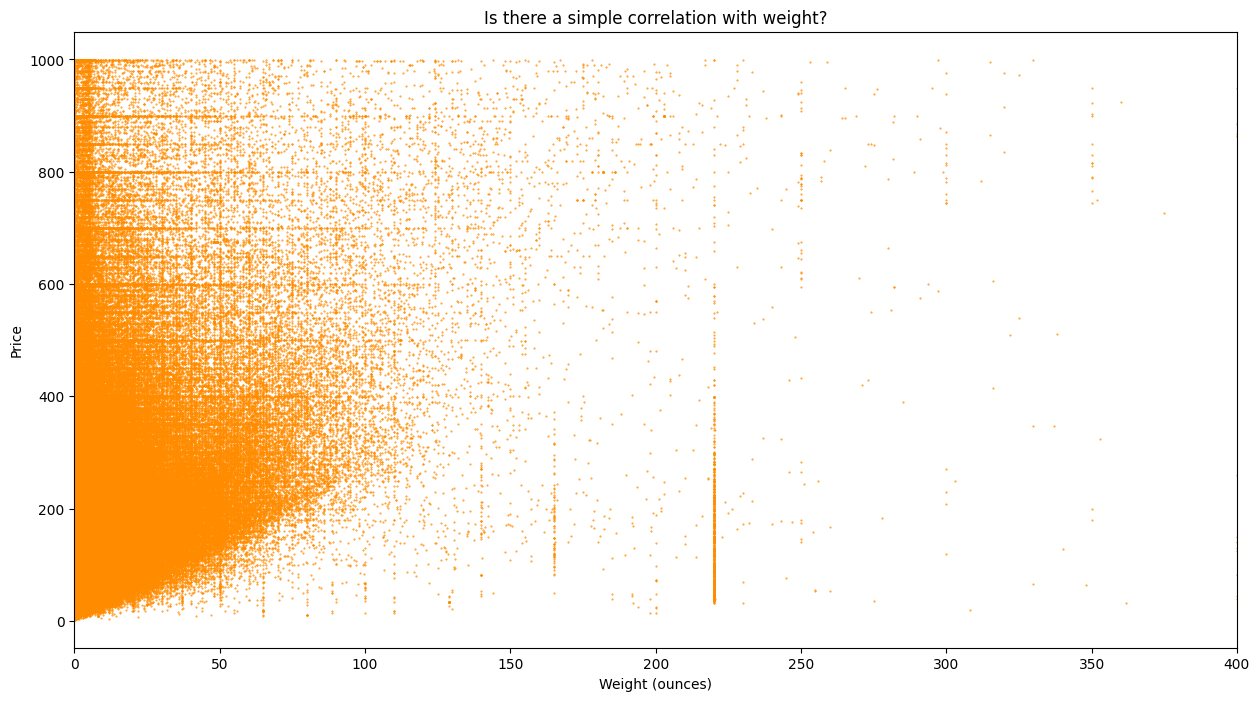

In [38]:
# How does the price vary with the weight?

ounces = [item.weight for item in sample]
prices = [item.price for item in sample]

# Create the scatter plot
plt.figure(figsize=(15, 8))
plt.scatter(ounces, prices, s=0.2, color="darkorange")

# Add labels and title
plt.xlabel('Weight (ounces)')
plt.ylabel('Price')
plt.xlim(0, 400)
plt.title('Is there a simple correlation with weight?')

# Display the plot
plt.show()

## Now push this dataset to the HuggingFace Hub

Replace the username with your HF username if you've crafted your own dataset

Or, ignore this cell and you can load my dataset tomorrow!

In [39]:
username = "ed-donner"
full = f"{username}/items_raw_full"
lite = f"{username}/items_raw_lite"

train = sample[:800_000]
val = sample[800_000:810_000]
test = sample[810_000:]

Item.push_to_hub(full, train, val, test)

train_lite = train[:20_000]
val_lite = val[:1_000]
test_lite = test[:1_000]

Item.push_to_hub(lite, train_lite, val_lite, test_lite)

KeyboardInterrupt: 

## Sidenote

If you like the variety of colors that matplotlib can use in its charts, you should bookmark this:

https://matplotlib.org/stable/gallery/color/named_colors.html
